In [46]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.cluster import KMeans

from utils import *

In [47]:
df = pd.read_csv('hqi_spectra.csv')
del df['Unnamed: 0']
df_int = interpol_spect(df, min_wl=674.9918, max_wl=3999.809,n=1725)
df_norm = norm_spect(df_int, norm_type='SNV')
df_norm_pivot = df_norm.pivot(index=['file_name', 'polymer'], 
               columns='wavelength', 
               values='intensity').reset_index()

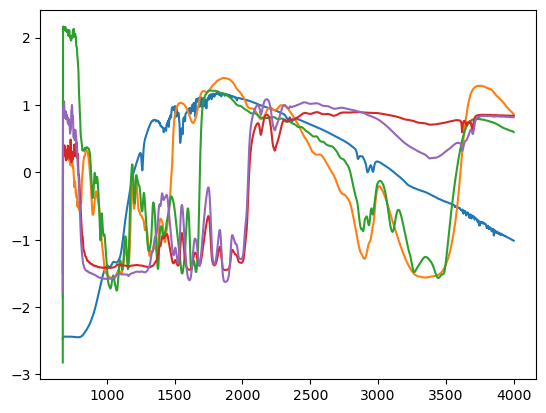

In [63]:
_ = plt.plot(df_norm_pivot.iloc[:,1:].groupby('polymer').mean().T)

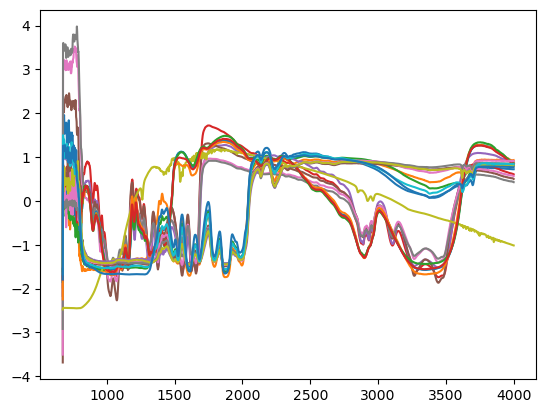

In [48]:
_ = plt.plot(df_norm_pivot.iloc[:,2:].T)

In [50]:
spectra_data_np_norm = df_norm_pivot.iloc[:,2:].to_numpy()

In [51]:
df_library = pd.read_csv('../spectral_data_all.csv')
df_library.drop(columns=['Unnamed: 0'], inplace=True)
df_flopp = df_library.query('data_source == "flopp" or data_source == "flopp_e"').reset_index(drop=True)
df_flopp = df_flopp.query('intensity > 0')
df_flopp = norm_spect(df_flopp, norm_type='SNV')
df_flopp_pivot = df_flopp.pivot(index=['file_name', 'polymer', 'data_source'], 
               columns='wavelength', 
               values='intensity').reset_index()

In [52]:
wl_list = df_flopp_pivot.columns[3:]
#df_flopp_pivot.columns = list(df_flopp_pivot.columns[:3]) + ['wl_' + str(round(x*100)) for x in df_flopp_pivot.columns[3:]]
polymer_list = df_flopp_pivot['polymer'].drop_duplicates().to_numpy()


#X_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,3:].reset_index(drop=True)
X_train = df_flopp_pivot.iloc[:,3:].reset_index(drop=True)
X_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,3:].reset_index(drop=True)

#y_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,1].reset_index(drop=True)
y_train = df_flopp_pivot.iloc[:,1].reset_index(drop=True)
y_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,1].reset_index(drop=True)

#X_train = X_train.reset_index(drop=True)
#y_train = y_train.reset_index(drop=True)
    
x_train = X_train.to_numpy()
x_test = X_test.to_numpy()
y_train_ = y_train.to_numpy()
y_train_[y_train_ == 'Nylon'] = 'Polyamide'
y_train_[y_train_ == 'Polyester'] = 'Polyethylene Terephthalate'

#x_train = x_train[:,idx_range]
#x_test = X_test.iloc[:,idx_range]

x_train = (x_train - x_train.mean(1)[:, None]) / x_train.std(1)[:, None]
x_test = (x_test - x_test.mean(1)[:, None]) / x_test.std(1)[:, None]

n, p = x_train.shape

In [53]:
clf = LogisticRegression(random_state=0, C=.1)
clf.fit(-x_train, y_train_)
clf.score(-x_test, y_test)

1.0

In [54]:
pred_prob = clf.predict_proba(spectra_data_np_norm).max(1) 
pred_poly = clf.predict(spectra_data_np_norm)

pred_polymers_hqi = corr_matching(-x_train, y_train, spectra_data_np_norm, r_min=0.7)[0].to_numpy()
pred_hqi = corr_matching(-x_train, y_train, spectra_data_np_norm, r_min=0.7)[1]#.to_numpy()

In [55]:
pred_poly, pred_prob

(array(['Polystyrene', 'Polystyrene', 'Polystyrene', 'Rubber', 'Rubber',
        'Rubber', 'Rubber', 'Rubber', 'Polypropylene', 'Rubber', 'Rubber',
        'Rubber', 'Rubber', 'Rubber', 'Polystyrene', 'Polystyrene',
        'Polystyrene', 'Polystyrene', 'Polystyrene', 'Polystyrene',
        'Polystyrene'], dtype=object),
 array([0.78598713, 0.76469038, 0.72620735, 0.97391114, 0.97396783,
        0.82869785, 0.42854277, 0.44066254, 0.31259959, 0.91822039,
        0.91822039, 0.91504037, 0.91660336, 0.90093238, 0.64085588,
        0.6790644 , 0.60869691, 0.60403186, 0.65691897, 0.77541695,
        0.80653598]))

In [56]:
pred_polymers_hqi, pred_hqi

(array(['Polystyrene', 'Polyethylene', 'Polyethylene', 'Rubber', 'Rubber',
        'Polystyrene', 'Polystyrene', 'Polystyrene', 'Rubber', 'Rubber',
        'Rubber', 'Rubber', 'Rubber', 'Rubber', 'Polyethylene',
        'Polyethylene', 'Polyethylene', 'Polyethylene', 'Polyethylene',
        'Polyethylene', 'Polyethylene'], dtype=object),
 array([ 0.18116   ,  0.17142202,  0.18925574,  0.02085831,  0.01161816,
         0.16517213,  0.30337659,  0.38526956,  0.11390445, -0.04086935,
        -0.04086935, -0.04144785, -0.05136465, -0.04057033,  0.1877248 ,
         0.18117533,  0.18309194,  0.17411263,  0.17999928,  0.18196169,
         0.18209169]))

In [66]:
pd.DataFrame({'label':df_norm_pivot.iloc[:,1],'pred_poly':pred_polymers_hqi,'hqi':pred_hqi}).to_csv('hqi_matches.csv')

In [44]:
def conform_pref_2(cal_smx, val_smx, cal_labels, n, alpha, val_labels=None):
    # Get scores. calib_X.shape[0] == calib_Y.shape[0] == n
    cal_pi = cal_smx.argsort(1)[:, ::-1]
    cal_srt = np.take_along_axis(cal_smx, cal_pi, axis=1).cumsum(axis=1)
    cal_scores = np.take_along_axis(cal_srt, cal_pi.argsort(axis=1), axis=1)[
        range(n), cal_labels
    ]
    # Get the score quantile
    qhat = np.quantile(
        cal_scores, np.ceil((n + 1) * (1 - alpha)) / n, interpolation="higher"
    )
    # Deploy (output=list of length n, each element is tensor of classes)
    val_pi = val_smx.argsort(1)[:, ::-1]
    val_srt = np.take_along_axis(val_smx, val_pi, axis=1).cumsum(axis=1)
    prediction_sets = np.take_along_axis(val_srt <= qhat, val_pi.argsort(axis=1), axis=1)

    if val_labels is None: 
        return prediction_sets
    # Calculate empirical coverage
    empirical_coverage = prediction_sets[
        np.arange(prediction_sets.shape[0]), val_labels
    ].mean()
    #print(f"The empirical coverage is: {empirical_coverage}")
    
    return (prediction_sets, empirical_coverage)

In [45]:
n_ref = X_train.shape[0]
df_R = np.corrcoef(X_train,  X_test)[:n_ref, n_ref:]

#df_R = 1-df_R
#df_R = np.exp(-df_R/.1)

df_R = pd.DataFrame(df_R)
df_R['polymer_ref'] = y_train
smx = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()

#sns.heatmap(pd.DataFrame(smx))
#pd.DataFrame(smx)
#smx = (smx / smx.sum(1)[:,None])
#smx = 1-smx
labels = y_test.reset_index().merge(pd.DataFrame({'id':range(15), 'polymer':np.unique((y_train).to_numpy())}))['id'].to_numpy()

# Problem setup
n=100 # number of calibration points
alpha = 0.1 # 1-alpha is the desired coverage

ValueError: All arrays must be of the same length